# GitHub Repository:
https://github.com/Munkhzaya-pom/statistic-sep-26

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("bank-full.csv", sep=";")

In [3]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [4]:
df.shape

(45211, 17)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [6]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [7]:
df.duplicated().sum()

0

In [8]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [10]:
mean = df['age'].mean()
median = df['age'].median()
mode = df['age'].mode()

print("Mean:", mean)
print("Median:", median)
print("Mode:", mode)

Mean: 40.93621021432837
Median: 39.0
Mode: 0    32
Name: age, dtype: int64


In [11]:
# Measures of Dispersion

age_range = df['age'].max() - df['age'].min()
variance = df['age'].var()
std = df['age'].std()

print("Range:", age_range)
print("Variance:", variance)
print("Standard Deviation:", std)

Range: 77
Variance: 112.75810728286069
Standard Deviation: 10.618762040975431


In [12]:
Q1 = df['age'].quantile(0.25)
Q3 = df['age'].quantile(0.75)
IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 33.0
Q3: 48.0
IQR: 15.0


### Age Distribution

I selected the age column to understand the age distribution of bank customers. I calculated the mean, median and standard deviation to understand the data. I used a histogram to see which age groups are most common and a boxplot to identify possible outliers.

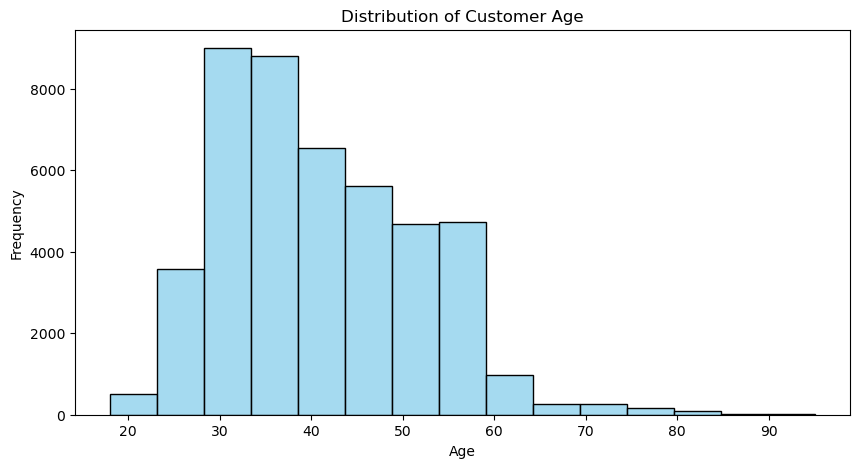

In [13]:
plt.figure(figsize=(10, 5))
sns.histplot(df['age'], bins=15, color='skyblue')

plt.title('Distribution of Customer Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

In [14]:
# Skewness of Customer Age
df['age'].skew()

0.6848179257252598

Histogram shows most customers are approximately between 28-60 years old. the distribution is positively skewed and few customers are older age groups.The mean age 40.94 is slightly higher than the median 39, which is consistent with the positive skewness 0.685 observed in the age distribution.

### Age Boxplot

A boxplot was used to examine the median, quartiles, and potential outliers in customer ages.

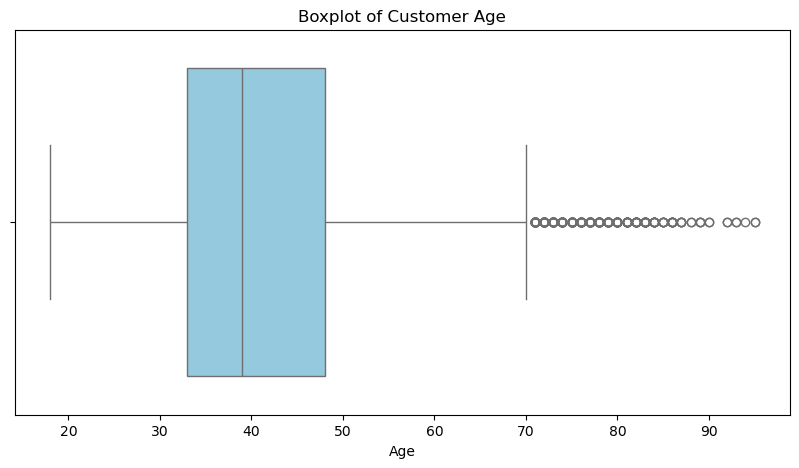

In [15]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['age'], color='skyblue')

plt.title('Boxplot of Customer Age')
plt.xlabel('Age')
plt.show()

The boxplot shows that 50% of customers are between 33 and 48 years old. The median age is 39. There are also some outliers above 70 years old. This means that some customers are much older than most others. The result is similar to the histogram, where most customers are in the younger and middle-aged groups.

### Balance Distribution


Customer balance was selected to examine how account balances vary between customers. Descriptive statistics were calculated to understand the average balance and the variation in the data. The IQR method was also used to identify possible outliers.

In [16]:
# Descriptive Statistics of Balance

print("Mean:", df['balance'].mean())
print("Median:", df['balance'].median())
print("Standard Deviation:", df['balance'].std())

Mean: 1362.2720576850766
Median: 448.0
Standard Deviation: 3044.7658291686002


In [17]:
# Detect outliers in balance

Q1 = df['balance'].quantile(0.25)
Q3 = df['balance'].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Lower bound:", lower)
print("Upper bound:", upper)

Lower bound: -1962.0
Upper bound: 3462.0


In [18]:
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 72.0
Q3: 1428.0
IQR: 1356.0


In [19]:
outliers = df[(df['balance'] < lower) | (df['balance'] > upper)]

print("Number of outliers:", len(outliers))

Number of outliers: 4729


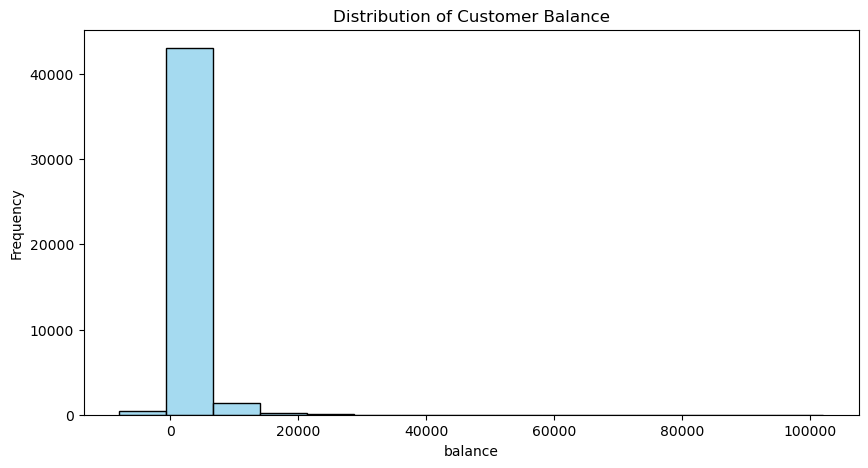

In [20]:
plt.figure(figsize=(10, 5))
sns.histplot(df['balance'], bins=15, color='skyblue')

plt.title('Distribution of Customer Balance')
plt.xlabel('balance')
plt.ylabel('Frequency')
plt.show()

In [21]:
# Skewness of Customer Balance
df['balance'].skew()

8.360308326166326

The histogram shows that most customers have low account balances, while a few have very high balances. The distribution is strongly right-skewed skewness = 8.36. The mean balance is 1,362.27, which is much higher than the median of 448. This suggests that a small number of high balances increase the average.

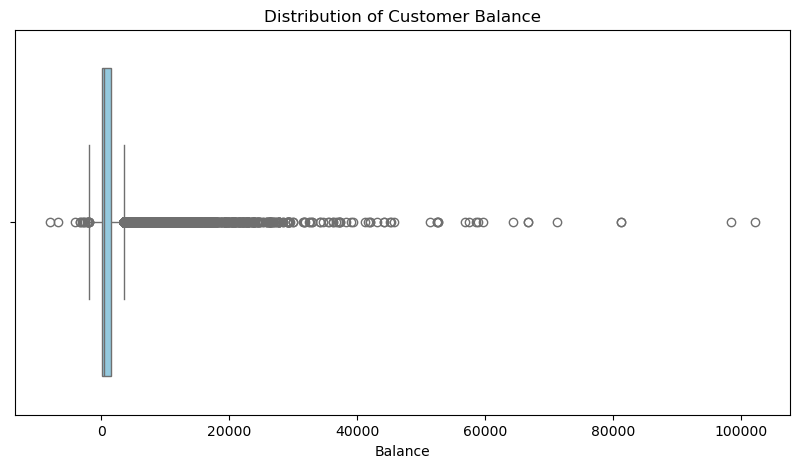

In [22]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['balance'], color='skyblue')
plt.title('Distribution of Customer Balance')
plt.xlabel('Balance')
plt.show()

The boxplot shows that most account balances are concentrated at lower values. The median balance is 448, and the middle 50% of balances are between 72 and 1,428. Using the IQR method, 4,729 outliers (10.46%) were identified. These values are below -1,962 or above 3,462. This shows that some customers have very different balances compared to others.

### Binomial distribution


In [23]:
p = (df["y"] == "yes").mean()
print("Probability of yes:", p)

Probability of yes: 0.11698480458295547


In [24]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom

# Parameters
n = 10
p = (df["y"] == "yes").mean()
x = np.arange(0, n+1)

# PMF and CDF
pmf = binom.pmf(x, n, p)
cdf = binom.cdf(x, n, p)

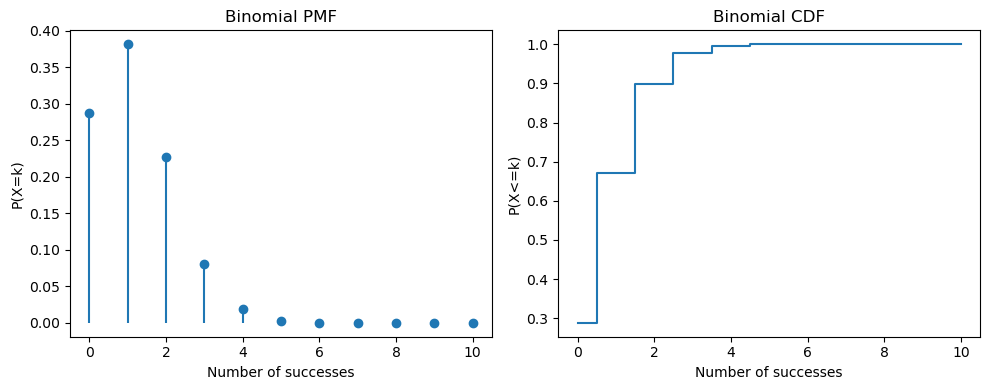

In [25]:
plt.figure(figsize=(10, 4))

# PMF Plot
plt.subplot(1, 2, 1)
plt.stem(x, pmf, basefmt=" ")
plt.title("Binomial PMF")
plt.xlabel("Number of successes")
plt.ylabel("P(X=k)")

# CDF Plot
plt.subplot(1, 2, 2)
plt.step(x, cdf, where="mid")
plt.title("Binomial CDF")
plt.xlabel("Number of successes")
plt.ylabel("P(X<=k)")

plt.tight_layout()
plt.show()

#The Binomial distribution was used to estimate how many customers might subscribe to a term deposit out of 10 customers. The probability of success (p) is approximately 0.117, based on the dataset.

In [26]:
# Parameters
n = 100
p = (df["y"] == "yes").mean()
x = np.arange(0, n+1)

# PMF and CDF
pmf = binom.pmf(x, n, p)
cdf = binom.cdf(x, n, p)

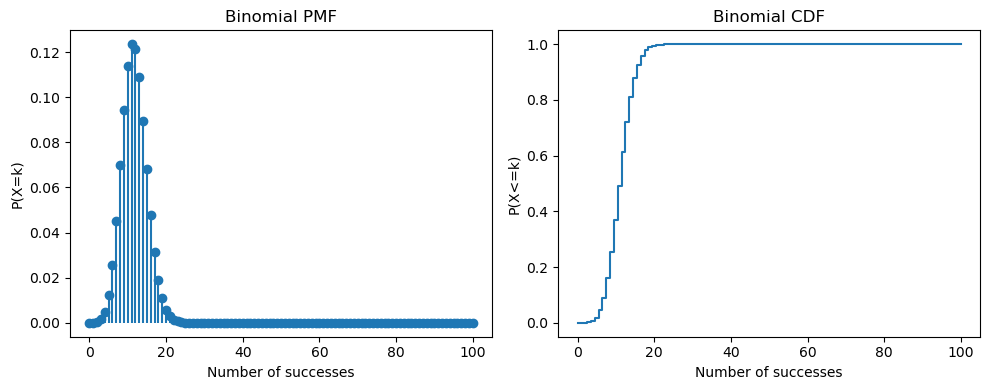

In [27]:
plt.figure(figsize=(10, 4))

# PMF Plot
plt.subplot(1, 2, 1)
plt.stem(x, pmf, basefmt=" ")
plt.title("Binomial PMF")
plt.xlabel("Number of successes")
plt.ylabel("P(X=k)")

# CDF Plot
plt.subplot(1, 2, 2)
plt.step(x, cdf, where="mid")
plt.title("Binomial CDF")
plt.xlabel("Number of successes")
plt.ylabel("P(X<=k)")

plt.tight_layout()
plt.show()

In [28]:
n = 10
p = (df['y'] == 'yes').mean()

np.random.seed(42)

sample_100 = np.random.binomial(n, p, size=100)
sample_1000 = np.random.binomial(n, p, size=1000)
sample_10000 = np.random.binomial(n, p, size=10000)

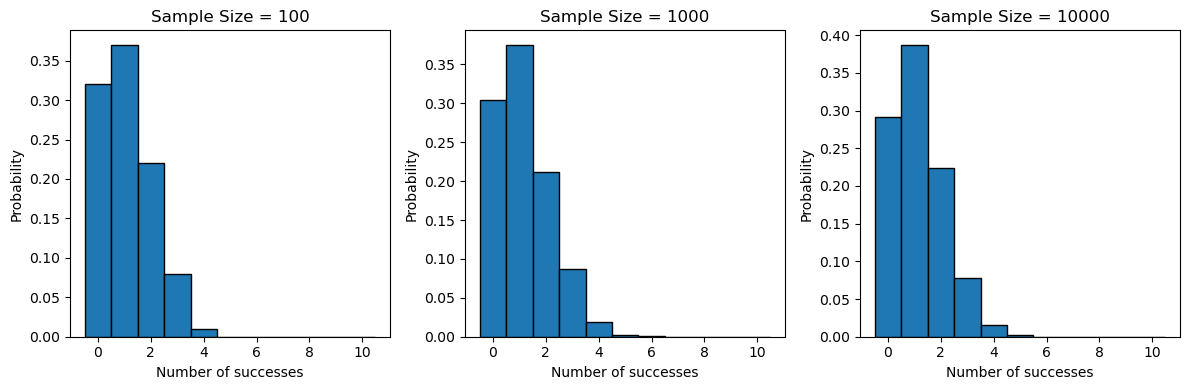

In [29]:
# Compare sample sizes

plt.figure(figsize=(12, 4))

samples = [sample_100, sample_1000, sample_10000]
sizes = [100, 1000, 10000]

for i in range(3):
    plt.subplot(1, 3, i + 1)

    plt.hist(samples[i], bins=np.arange(-0.5, n + 1.5, 1), density=True, edgecolor='black')

    plt.title(f'Sample Size = {sizes[i]}')
    plt.xlabel('Number of successes')
    plt.ylabel('Probability')

plt.tight_layout()
plt.show()

In [30]:
print("Theoretical Mean:", n * p)

print("Sample 100 Mean:", sample_100.mean())
print("Sample 1000 Mean:", sample_1000.mean())
print("Sample 10000 Mean:", sample_10000.mean())

Theoretical Mean: 1.1698480458295548
Sample 100 Mean: 1.09
Sample 1000 Mean: 1.152
Sample 10000 Mean: 1.1494


In [31]:
n = 10
p = (df['y'] == 'yes').mean()

np.random.seed(42)

sample_1000 = np.random.binomial(n, p, size=1000)
sample_10000 = np.random.binomial(n, p, size=10000)
sample_100000 = np.random.binomial(n, p, size=100000)

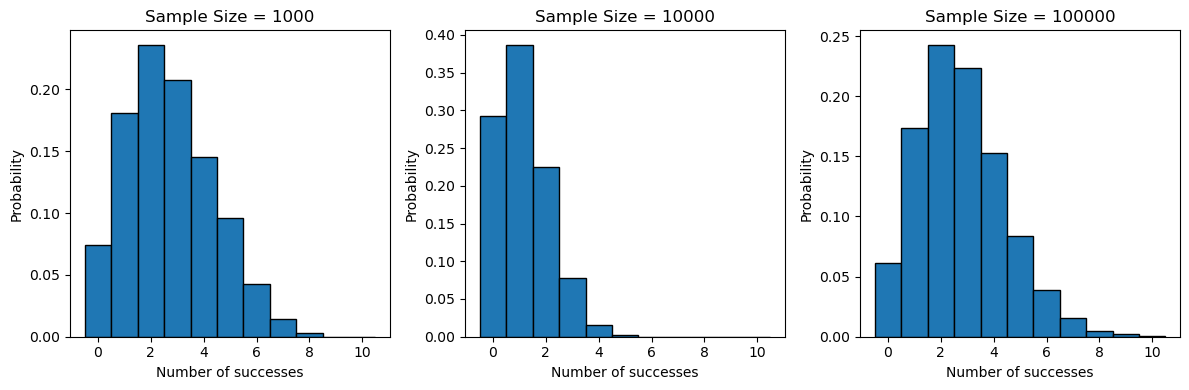

In [43]:
# Compare sample sizes

plt.figure(figsize=(12, 4))

samples = [sample_1000, sample_10000, sample_100000]
sizes = [1000, 10000, 100000]

for i in range(3):
    plt.subplot(1, 3, i + 1)

    plt.hist(samples[i], bins=np.arange(-0.5, n + 1.5, 1), density=True, edgecolor='black')

    plt.title(f'Sample Size = {sizes[i]}')
    plt.xlabel('Number of successes')
    plt.ylabel('Probability')

plt.tight_layout()
plt.show()

In [33]:
print("Theoretical Mean:", n * p)

print("Sample 1000 Mean:", sample_1000.mean())
print("Sample 10000 Mean:", sample_10000.mean())
print("Sample 100000 Mean:", sample_100000.mean())

Theoretical Mean: 1.1698480458295548
Sample 1000 Mean: 1.128
Sample 10000 Mean: 1.1491
Sample 100000 Mean: 1.16776


#Binomial Large Sample Simulation 

I used the Binomial distribution to simulate 1,000, 10,000 and 100,000 trials. Each trial had 10 customers, and the probability of success was 0.117. The expected mean was 1.1698, while the sample means were 1.128, 1.1491 and 1.16776.

The graphs looked similar, but as the number of trials increased, the sample mean got closer to the expected mean. This shows how the Law of Large Numbers works.

# Poisson distribution

In [34]:
campaign_mean = df["campaign"].mean()
campaign_var = df["campaign"].var()

print("Mean:", campaign_mean)
print("Variance:", campaign_var)

Mean: 2.763840658246887
Variance: 9.597733393240356


In [35]:
from scipy.stats import poisson

x = np.arange(0, df["campaign"].max() + 1)

pmf = poisson.pmf(x, campaign_mean)
cdf = poisson.cdf(x, campaign_mean)

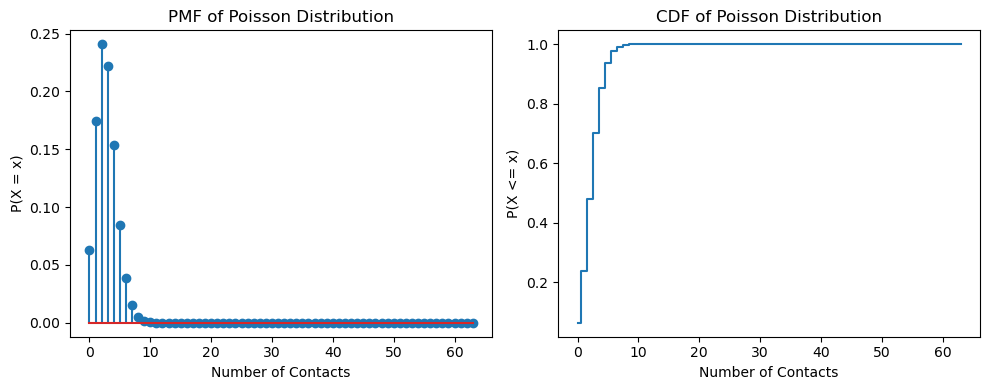

In [36]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.stem(x, pmf)
plt.title("PMF of Poisson Distribution")
plt.xlabel("Number of Contacts")
plt.ylabel("P(X = x)")

plt.subplot(1, 2, 2)
plt.step(x, cdf, where="mid")
plt.title("CDF of Poisson Distribution")
plt.xlabel("Number of Contacts")
plt.ylabel("P(X <= x)")

plt.tight_layout()
plt.show()

In [37]:
# Probability of exactly 3 contacts
p_exactly_3 = poisson.pmf(3, campaign_mean)

# Probability of at most 3 contacts
p_at_most_3 = poisson.cdf(3, campaign_mean)

print("P(X = 3):", p_exactly_3)
print("P(X <= 3):", p_at_most_3)

P(X = 3): 0.2218538689875246
P(X <= 3): 0.6999712444293309


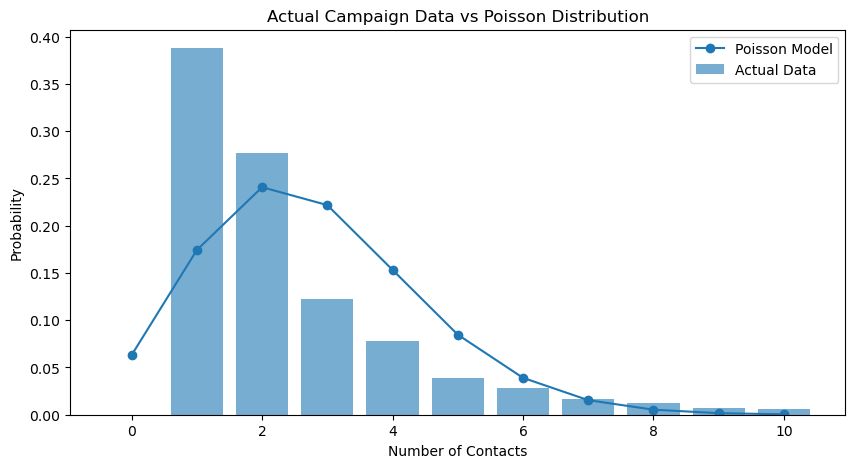

In [38]:
# Compare actual data with Poisson distribution

x = np.arange(0, 11)

actual = df['campaign'].value_counts(normalize=True)
theoretical = poisson.pmf(x, campaign_mean)

plt.figure(figsize=(10, 5))

plt.bar(x, actual.reindex(x, fill_value=0),alpha=0.6, label='Actual Data')

plt.plot(x, theoretical, 'o-',label='Poisson Model')

plt.title('Actual Campaign Data vs Poisson Distribution')
plt.xlabel('Number of Contacts')
plt.ylabel('Probability')
plt.legend()
plt.show()

The data shows that most customers were contacted once in actual data but in Poisson model shows ttwo contact is the highest probabillity. This difference shows that Poisson model not fits on our actual data very well. In theory MEAN=VARIANCE=LAMBDA. 

In [46]:
# Poisson Large Sample Simulation

lam = df['campaign'].mean()

np.random.seed(42)

poisson_1000 = np.random.poisson(lam, size=1000)
poisson_100000 = np.random.poisson(lam, size=100000)

print("Theoretical Mean:", lam)
print("Poisson Sample Mean (1000):", poisson_1000.mean())
print("Poisson Sample Mean (100000):", poisson_100000.mean())

Theoretical Mean: 2.763840658246887
Poisson Sample Mean (1000): 2.717
Poisson Sample Mean (100000): 2.76671


The theoretical mean of the Poisson distribution is 2.76. When the sample size was 1,000, the poisson sample mean was 2.717. When the sample size increased to 100,000, the poisson sample mean was 2.767, which is closer to the theoretical mean. This shows that larger samples tend to give more stable results and the sample mean gets closer to the theoretical mean. This is an example of the Law of Large Numbers.

### Normal distribution

Mean: 40.93621021432837
Standard Deviation: 10.618762040975431


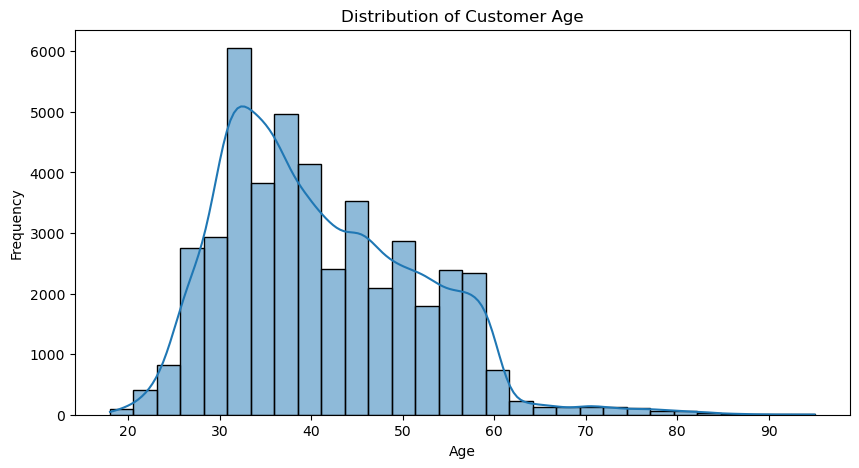

In [40]:
# Normal Distribution - Age

age_mean = df['age'].mean()
age_std = df['age'].std()

print("Mean:", age_mean)
print("Standard Deviation:", age_std)

plt.figure(figsize=(10, 5))
sns.histplot(df['age'], bins=30, kde=True)

plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

In [41]:
# Empirical Rule for Age

age = df['age']

within1 = ((age >= age_mean - age_std) & (age <= age_mean + age_std)).mean() * 100

within2 = ((age >= age_mean - 2*age_std) & (age <= age_mean + 2*age_std)).mean() * 100

within3 = ((age >= age_mean - 3*age_std) & (age <= age_mean + 3*age_std)).mean() * 100

print("Within 1 SD:", within1)
print("Within 2 SD:", within2)
print("Within 3 SD:", within3)

Within 1 SD: 66.0502974939727
Within 2 SD: 97.77045409303045
Within 3 SD: 99.15728473159187


The empirical rule states that approximately 68%, 95%, and 99.7% of data should fall within one, two, and three standard deviations of the mean in a normal distribution.

In our dataset, the results are 66.05%, 97.77%, and 99.16%. These values are close to the theoretical percentages, but they are not exactly the same.

This suggests that the age data has some characteristics of a normal distribution, but it does not follow a perfect normal distribution.

#Q-Q plot

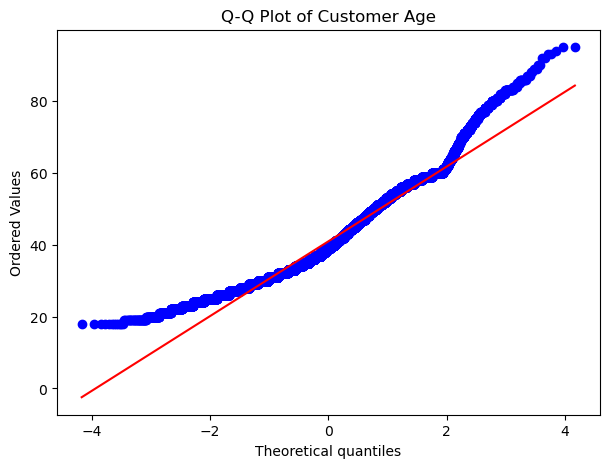

In [42]:
from scipy import stats
import matplotlib.pyplot as plt
plt.figure(figsize=(7, 5))

stats.probplot(df['age'], dist='norm', plot=plt)

plt.title("Q-Q Plot of Customer Age")
plt.show()

The Q–Q plot shows that points are close to the straight line in the middle, but they move away from the line at both ends. 
This suggests that the age data does not follow a perfect normal distribution. 
The main reason is that the age data is right-skewed rather than symmetric. Most customers are between 30 and 40 years old, while some older customers create a longer tail on the right. The Q–Q plot also shows that the points move away from the straight line at both ends. Therefore, the age data does not closely follow a normal distribution.